# 12 · How uncertain are the numbers? Bootstrap and repeated splits
Every number so far comes from one split and one test set. Two different sources of uncertainty hide behind that:

1. **Test-set sampling** (a different sample of people would give slightly different metrics). We measure it with a bootstrap of the test set (1,000 resamples; the models are fixed).
2. **Training and splitting** (a different split, or a different random seed, would give a different model). We measure it by repeating the whole pipeline (split → train with early stopping → threshold on validation → test) with five other seeds.

All thresholds follow the same rule as before: recall ≥ 80 % on the validation set.

In [ ]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
DROP = ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]; keep = [c for c in X_tr.columns if c not in DROP]
lr, full, red = (joblib.load(f"../models/{n}.joblib") for n in ["logreg", "lightgbm", "lightgbm_reduced"])
P  = {"logreg": lr.predict_proba(X_te)[:, 1], "full": full.predict_proba(X_te)[:, 1], "reduced": red.predict_proba(X_te[keep])[:, 1]}
PV = {"full": full.predict_proba(X_va)[:, 1], "reduced": red.predict_proba(X_va[keep])[:, 1]}
THR = {k: threshold_for_recall(y_va, PV[k], 0.80) for k in PV}
print({k: round(v, 3) for k, v in THR.items()})

def groups_of(X):   # same definition as notebook 07
    return pd.DataFrame({"age": pd.cut(X.Age, [0, 5, 9, 13], labels=["18-44", "45-64", "65+"]).astype(str),
                         "income": pd.cut(X.Income, [0, 4, 6, 8], labels=["low", "middle", "high"]).astype(str)}, index=X.index)

{'full': np.float64(0.148), 'reduced': np.float64(0.147)}


## 1. Bootstrap of the test set (models fixed)
Each resample draws 34,422 people with replacement from the test set and recomputes every metric. We report the value on the real test set and the 95 % percentile interval. Differences between models are computed inside each resampl (paired), which is the right way to ask "is A really better than B?".

In [2]:
y = y_te.values; n = len(y); G = groups_of(X_te)
yhat = {k: P[k] >= THR[k] for k in THR}
masks = {"age 18-44": (G.age == "18-44").values, "age 45-64": (G.age == "45-64").values, "age 65+": (G.age == "65+").values,
         "income low": (G.income == "low").values, "income high": (G.income == "high").values, "no cholesterol check": (X_te.CholCheck == 0).values}
def rec(k, idx, m=None):
    pos = (y[idx] == 1) if m is None else (y[idx] == 1) & m[idx]
    return (yhat[k][idx] & pos).sum() / pos.sum()
def metrics(idx):
    yy = y[idx]; o = {}
    for k in P: o[f"AUC {k}"] = roc_auc_score(yy, P[k][idx])
    o["PR-AUC full"] = average_precision_score(yy, P["full"][idx]); o["PR-AUC logreg"] = average_precision_score(yy, P["logreg"][idx])
    o["dAUC full - logreg"] = o["AUC full"] - o["AUC logreg"]; o["dAUC reduced - full"] = o["AUC reduced"] - o["AUC full"]
    for k in ("full", "reduced"):
        o[f"recall {k}"] = rec(k, idx); o[f"flagged {k}"] = yhat[k][idx].mean()
        o[f"precision {k}"] = yy[yhat[k][idx]].mean()
    for g, m in masks.items():
        o[f"recall reduced | {g}"] = rec("reduced", idx, m)
    o["recall gap age (reduced)"] = o["recall reduced | age 65+"] - o["recall reduced | age 18-44"]
    o["recall gap income (reduced)"] = o["recall reduced | income low"] - o["recall reduced | income high"]
    o["recall full | no cholesterol check"] = rec("full", idx, masks["no cholesterol check"])
    o["dRecall reduced - full | no chol. check"] = o["recall reduced | no cholesterol check"] - o["recall full | no cholesterol check"]
    return o
rng = np.random.default_rng(0)
point = metrics(np.arange(n))
boot = pd.DataFrame([metrics(rng.integers(0, n, n)) for _ in range(1000)])
tab = pd.DataFrame({"test set": pd.Series(point), "boot mean": boot.mean(), "2.5 %": boot.quantile(.025), "97.5 %": boot.quantile(.975)}).round(3)
tab

,test set,boot mean,2.5 %,97.5 %
AUC logreg,0.807,0.807,0.801,0.813
AUC full,0.818,0.818,0.812,0.824
AUC reduced,0.815,0.815,0.809,0.821
PR-AUC full,0.442,0.443,0.429,0.457
PR-AUC logreg,0.404,0.404,0.390,0.418
dAUC full - logreg,0.011,0.011,0.009,0.013
dAUC reduced - full,-0.003,-0.003,-0.004,-0.002
recall full,0.799,0.799,0.789,0.810
flagged full,0.390,0.390,0.385,0.395
precision full,0.313,0.314,0.306,0.322


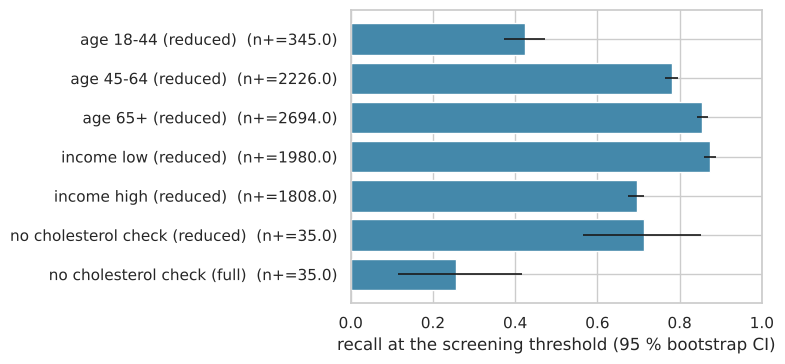

,recall,lo,hi,n_pos
age 18-44 (reduced),0.423,0.372,0.473,345
age 45-64 (reduced),0.781,0.763,0.797,2226
age 65+ (reduced),0.856,0.843,0.869,2694
income low (reduced),0.875,0.860,0.889,1980
income high (reduced),0.695,0.674,0.715,1808
no cholesterol check (reduced),0.714,0.564,0.852,35
no cholesterol check (full),0.257,0.115,0.417,35


In [3]:
sub = pd.DataFrame({"recall": [point[f"recall reduced | {g}"] for g in masks] + [point["recall full | no cholesterol check"]],
                    "lo": [boot[f"recall reduced | {g}"].quantile(.025) for g in masks] + [boot["recall full | no cholesterol check"].quantile(.025)],
                    "hi": [boot[f"recall reduced | {g}"].quantile(.975) for g in masks] + [boot["recall full | no cholesterol check"].quantile(.975)],
                    "n_pos": [int(((y == 1) & m).sum()) for m in masks.values()] + [int(((y == 1) & masks["no cholesterol check"]).sum())]},
                   index=[f"{g} (reduced)" for g in masks] + ["no cholesterol check (full)"])
fig, ax = plt.subplots(figsize=(8, 3.8)); ypos = np.arange(len(sub))[::-1]
ax.barh(ypos, sub.recall, color="#48a"); ax.errorbar(sub.recall, ypos, xerr=[sub.recall - sub.lo, sub.hi - sub.recall], fmt="none", c="k", lw=1.2)
ax.set_yticks(ypos); ax.set_yticklabels([f"{i}  (n+={r.n_pos})" for i, r in sub.iterrows()]); ax.set_xlabel("recall at the screening threshold (95 % bootstrap CI)"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.savefig("../figures/uncertainty_subgroups.png", dpi=150); plt.show(); sub.round(3)

## 2. Repeating the whole pipeline with other seeds
For each seed: new stratified split (same 70/15/15 recipe), new LightGBM (same hyper-parameters, early stopping on that seed's validation set, random_state = seed), threshold from that seed's validation set, evaluation on that seed's test set. Full model = 21 features, reduced = 18.

In [4]:
def fit_gbm(Xtr, ytr, Xva, yva, seed):
    m = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.03, num_leaves=15, min_child_samples=100, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=5.0, random_state=seed, verbose=-1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="binary_logloss", callbacks=[lgb.early_stopping(100, verbose=False)]); return m
rows = []
for seed in [0, 1, 2, 3, 4]:
    Xa, Xb, Xc, ya, yb, yc = get_splits(seed=seed); Gc = groups_of(Xc); o = {"seed": seed}
    for name, cols in [("full", list(Xa.columns)), ("reduced", keep)]:
        m = fit_gbm(Xa[cols], ya, Xb[cols], yb, seed); pv, pt = m.predict_proba(Xb[cols])[:, 1], m.predict_proba(Xc[cols])[:, 1]
        thr = threshold_for_recall(yb, pv, 0.80); yh = pt >= thr; pos = yc.values == 1
        o[f"AUC {name}"] = roc_auc_score(yc, pt); o[f"recall {name}"] = yh[pos].mean(); o[f"precision {name}"] = yc.values[yh].mean(); o[f"flagged {name}"] = yh.mean()
        nochol = (Xc.CholCheck == 0).values & pos
        o[f"recall no chol. check {name}"] = yh[nochol].mean()
        if name == "reduced":
            r = lambda g, a: yh[pos & (Gc[a] == g).values].mean()
            o["age gap (65+ minus 18-44)"] = r("65+", "age") - r("18-44", "age"); o["income gap (low minus high)"] = r("low", "income") - r("high", "income")
    o["dAUC reduced - full"] = o["AUC reduced"] - o["AUC full"]; rows.append(o); print("seed", seed, "done")
R = pd.DataFrame(rows).set_index("seed")
summary = pd.DataFrame({"mean": R.mean(), "sd": R.std(), "min": R.min(), "max": R.max()}).round(3); summary

seed 0 done


seed 1 done


seed 2 done


seed 3 done


seed 4 done


,mean,sd,min,max
AUC full,0.817,0.002,0.814,0.819
recall full,0.798,0.006,0.790,0.805
precision full,0.313,0.003,0.309,0.317
flagged full,0.390,0.007,0.381,0.399
recall no chol. check full,0.368,0.053,0.312,0.448
AUC reduced,0.813,0.002,0.810,0.817
recall reduced,0.799,0.007,0.789,0.806
precision reduced,0.309,0.004,0.303,0.312
flagged reduced,0.396,0.007,0.387,0.406
recall no chol. check reduced,0.752,0.052,0.694,0.795


## 3. Conclusion

- **The overall model results are quite close:** LightGBM gets a ROC-AUC of 0.818 (95% CI: 0.812–0.824), while Logistic Regression gets 0.807 (0.801–0.813). The difference is +0.011 (0.009–0.013), meaning that boosting performs better, although the improvement is quite small. Removing the three shortcut features only reduces ROC-AUC by 0.003 (−0.004 to −0.002). This is a very small change, but it is consistent. At the screening threshold, the full model achieves a recall of 0.799 (0.789–0.810), a precision of 0.313 (0.306–0.322) and flags 39% of people.

- **The fairness gaps are real and not just random variation:** the recall gap between people aged 65+ and those aged 18–44 is 0.43 (0.38–0.48). For income, the gap between the low- and high-income groups is 0.18 (0.155–0.205). These results are also consistent across five other data splits and random seeds, with average gaps of 0.427 ± 0.026 and 0.194 ± 0.015, respectively.

- **The youngest group has less reliable estimates, but its results are clearly worse:** recall for people aged 18–44 is 0.42 (0.37–0.47), based on only 345 positive cases. So, even though the estimate is less precise, there is still a clear difference compared to the older groups.

- **The effect of removing shortcut features is consistent, but the exact size of the improvement is uncertain:** among people who have not had a cholesterol test, there are only 35 positive cases in the test set. Recall increases from 0.26 (0.12–0.42) with the full model to 0.71 (0.56–0.85) with the reduced model. The paired difference is +0.46 (0.29–0.63), so it is clearly above zero, but the confidence interval is quite wide. Across the five other splits, average recall is 0.37 for the full model and 0.75 for the reduced model, with a standard deviation of around 0.05 for both. The original split gives one of the lowest results for the full model, so the previously reported values (0.26 → 0.71) should be presented together with this wider range rather than as exact results.

- **Results are quite stable across different random seeds:** ROC-AUC is 0.817 ± 0.002 for the full model and 0.813 ± 0.002 for the reduced model. Screening recall is also very similar, at 0.798 ± 0.006 and 0.799 ± 0.007, respectively.

**Caveats:** the bootstrap only measures uncertainty coming from the test sample, keeping the models fixed. The repeated splits capture differences caused by training and data splitting, but they all come from the same 229,474 rows, meaning their test sets overlap. Therefore, the actual uncertainty when applying the model to completely new data may be somewhat higher. Also, none of these analyses solves the more general issues, such as detection bias in the diabetes labels or limitations in the survey design.